In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 


# Import Library of Machine Learning (Scikit-Learn)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC


In [2]:
df = pd.read_csv("iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df.shape

(150, 5)

In [4]:
for c in df['species'].unique():
    print(df[df['species'] == c].shape[0])

50
50
50


In [5]:
df['species'].unique()

<StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str

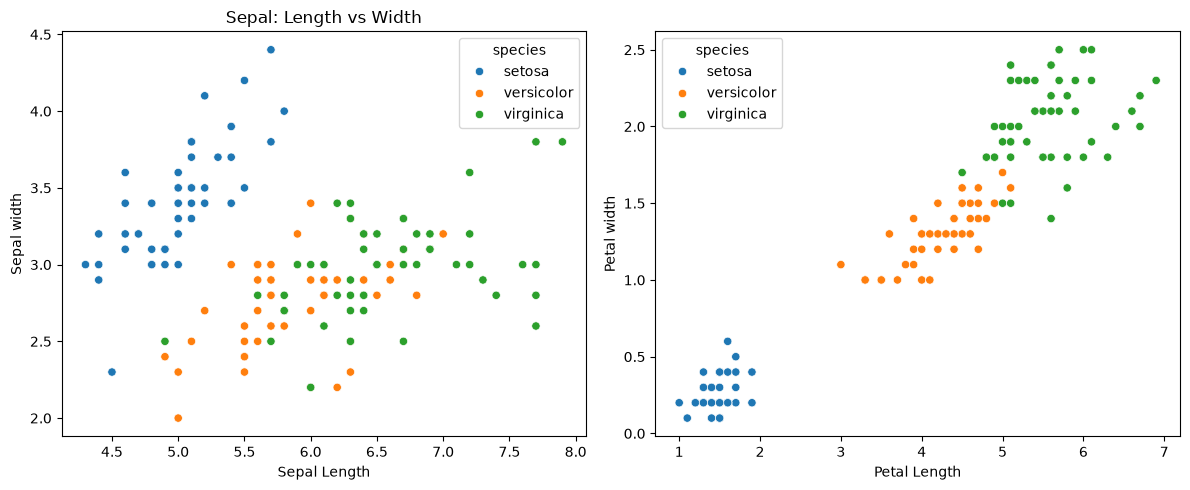

In [6]:
fig, axes = plt.subplots(1,2, figsize=(12,5))

sns.scatterplot(data=df, x="sepal_length", y="sepal_width", hue="species", ax=axes[0])
axes[0].set_title("Sepal: Length vs Width")
axes[0].set_xlabel("Sepal Length")
axes[0].set_ylabel("Sepal width")

sns.scatterplot(data=df, x="petal_length", y="petal_width",  ax=axes[1], hue="species")
axes[1].set_xlabel("Petal Length")
axes[1].set_ylabel("Petal width")

plt.tight_layout()
plt.show()

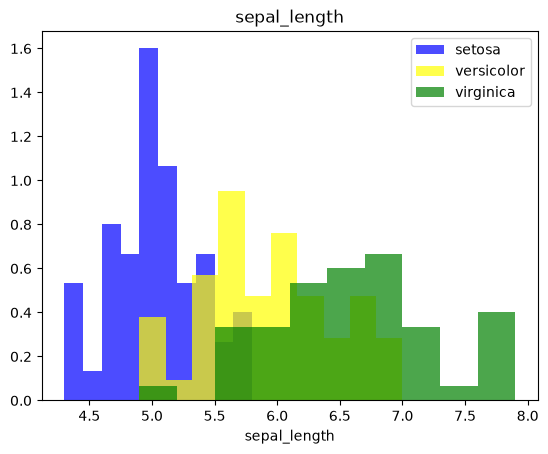

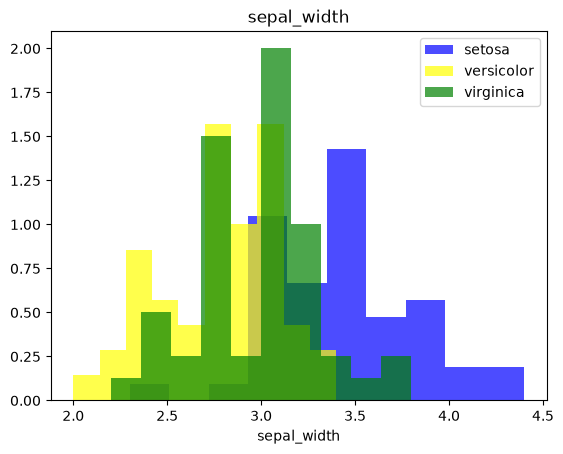

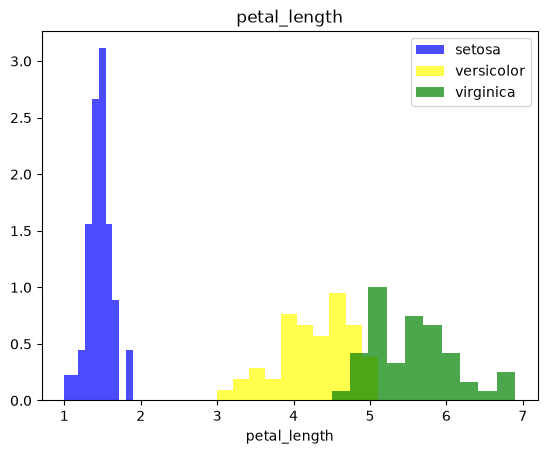

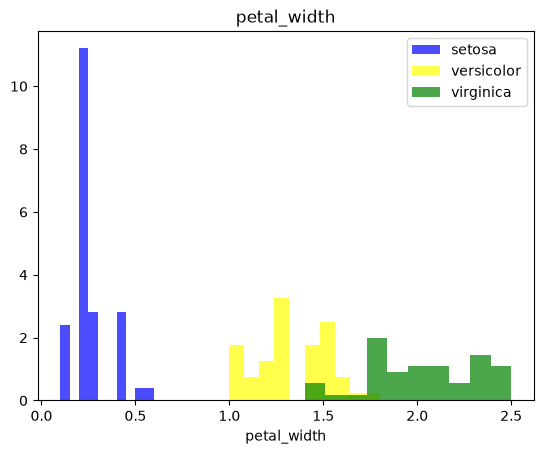

In [7]:
for label in df.columns[:-1]:
    plt.hist(df[df['species'] == "setosa" ][label], color="blue", label="setosa", alpha=0.7, density=True)
    plt.hist(df[df['species'] == "versicolor" ][label], color="yellow", label="versicolor", alpha=0.7, density=True)
    plt.hist(df[df['species'] == "virginica" ][label], color="green", label="virginica", alpha=0.7, density=True)
    plt.title(label)
    plt.legend()
    plt.xlabel(label)
    plt.show()

In [8]:
# Conversion de variable simple (species en int )
# setosa = 0, versicolor = 1, virginica = 2
le = LabelEncoder()
df['species_encoded'] = le.fit_transform(df['species'])
df['species_encoded'].value_counts()


species_encoded
0    50
1    50
2    50
Name: count, dtype: int64

In [9]:
X = df.drop(['species', 'species_encoded'], axis=1)
y = df['species_encoded']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y ,train_size=0.8, random_state=42)

In [11]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(120, 4)
(30, 4)
(120,)
(30,)


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [13]:
# ------------------------------------------
# Model 1: Logistic Regression
# ------------------------------------------

print("\nTraning Model Logistic Regression...")
lr_model = LogisticRegression()
lr_model.fit(X_train_scaled, y_train)

# evaluation 
y_pred_lr = lr_model.predict(X_test_scaled)
print(f"Accuracy Logistic Regression : {round((accuracy_score(y_test, y_pred_lr) * 100), 2)}")
print("\nClassification Report (Logistic Regression): ")
print(classification_report(y_test, y_pred_lr))



Traning Model Logistic Regression...
Accuracy Logistic Regression : 100.0

Classification Report (Logistic Regression): 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [14]:
# ------------------------------------------
# Model 2: Support Vector Machine (SVM)
# ------------------------------------------

print("\nSupport Vector Machines (SVM)")

svm_model = SVC(kernel="rbf")
svm_model.fit(X_train_scaled, y_train)

# evaluation 
y_pred_svm = svm_model.predict(X_test_scaled)
print(f"Accuracy SVM : {round((accuracy_score(y_test, y_pred_svm) * 100), 2)}")
print("\nClassification Report (SVM): ")
print(classification_report(y_test, y_pred_svm))



Support Vector Machines (SVM)
Accuracy SVM : 100.0

Classification Report (SVM): 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [15]:
# ------------------------------------------
# Model 3: K-Nearest Neighbors (KNN)
# ------------------------------------------

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# evaluation 
y_pred_knn = svm_model.predict(X_test_scaled)
print(f"Accuracy KNN : {round((accuracy_score(y_test, y_pred_knn) * 100), 2)}")
print("\nClassification Report (KNN): ")
print(classification_report(y_test, y_pred_knn))


Accuracy KNN : 100.0

Classification Report (KNN): 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [16]:
import warnings as wr 
wr.filterwarnings("ignore")

In [17]:
lr_scores = cross_val_score(lr_model, X, y, cv=5)
svm_scores = cross_val_score(svm_model, X, y, cv=5)
knn_scores = cross_val_score(knn_model, X, y, cv=5)

print("Logistic Regression accuracy:", lr_scores.mean())
print("Support Vector Machine accuracy:", svm_scores.mean())
print("K-Nearest Neighbors accuracy:", knn_scores.mean())

Logistic Regression accuracy: 0.9733333333333334
Support Vector Machine accuracy: 0.9666666666666666
K-Nearest Neighbors accuracy: 0.9733333333333334


In [18]:
### Prediction with new data  on logistic regression  model 
new_iris = [[5.1,3.5,1.4,0.2]]

new_iris_scaled = scaler.transform(new_iris)

prediction = lr_model.predict(new_iris_scaled)

print(f"Species predicted is: {prediction[0]}")

Species predicted is: 0


In [19]:
### Prediction with new data on SVM model
new_iris = [[6.3,3.3,6.0,2.5]]

new_iris_scaled = scaler.transform(new_iris)

prediction = svm_model.predict(new_iris_scaled)

print(f"Species predicted is: {prediction[0]}")

Species predicted is: 2


In [20]:
### Prediction with new data on KNN model
new_iris = [[2.3,3.3,5.0,2.5]]

new_iris_scaled = scaler.transform(new_iris)

prediction = knn_model.predict(new_iris_scaled)

print(f"Species predicted is: {prediction[0]}")

Species predicted is: 1
